In [2]:
%matplotlib inline
%reload_ext autoreload
%autoreload 2
%config InlineBackend.figure_format='retina'
import sys; print(sys.version)
sys.path.append('python-src')
from import_all_notebook_hook import *
import fastbook
fastbook.setup_book()
from fastbook import *

3.8.10 (default, Jun  4 2021, 15:09:15) 
[GCC 7.5.0]


/home/marian/anaconda3/envs/ml/lib/python3.8/site-packages/fastbook/__init__.py:18: UserWarning: Missing `graphviz` - please run `conda install fastbook`
  except ModuleNotFoundError: warn("Missing `graphviz` - please run `conda install fastbook`")


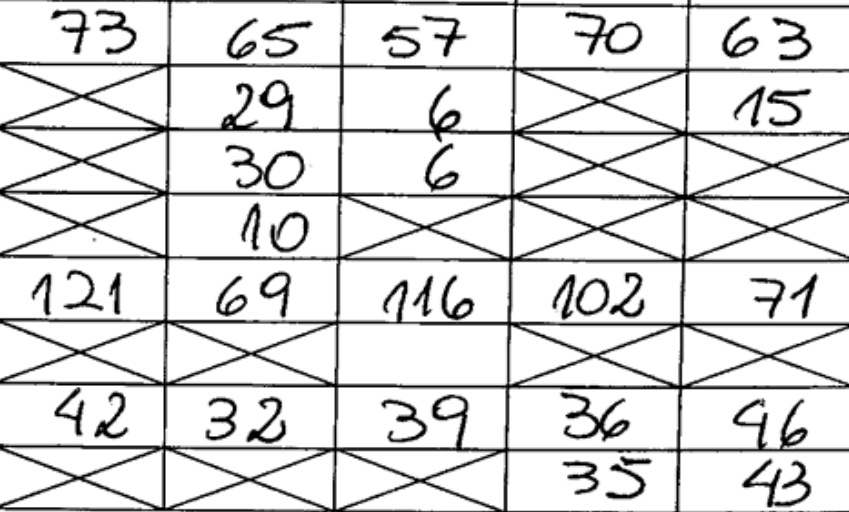

In [18]:
img = Image.open("numeros.png") # the second one 
img

In [19]:
text = pytesseract.image_to_string(img,config='digits')
text

' \n        \n\nSANS\nayia\n\nNe F\nWg V2cVieq\n\nSARS\n\n \n\n   \n\n    \n\n       \n\x0c'

In [3]:
def features_callback(sgn_fp):
    new_size = (174//4,127//4)
    img = Image.open(sgn_fp)
    img = img.resize(new_size, PIL.Image.ANTIALIAS)
    return np.array(img).flatten()

def outlier_out(x_plot,k):
    x_plot_mean = x_plot.mean()
    x_plot_std = x_plot.std()
    x_plot[ np.abs(x_plot-x_plot_mean)>k*x_plot_std ]=0
    return x_plot

def features_callback_2(sgn_fp):
    new_size = (174,127)
    img = Image.open(sgn_fp)
    img = preprocess_img(img)
    img = img.resize(new_size, PIL.Image.ANTIALIAS)
    np_img = np.array(img)
    np_img = outlier_out(np_img,2)
    np_img = outlier_out(np_img,2)
    np_img = outlier_out(np_img,2)
    return np_img.sum(axis=1)

In [4]:
fns = get_image_files('./cls_test')
fns

(#1494) [Path('cls_test/yes-signature/PDF-6251-51-0-PAG-0-fis1.PNG'),Path('cls_test/yes-signature/PDF-6053-52-0-PAG-0-aux2.PNG'),Path('cls_test/yes-signature/PDF-6218-51-6-PAG-0-presidente.PNG'),Path('cls_test/yes-signature/PDF-6232-51-8-PAG-0-aux1.PNG'),Path('cls_test/yes-signature/PDF-6043-51-1-PAG-0-jefe.PNG'),Path('cls_test/yes-signature/PDF-6344-51-1-PAG-0-aux2.PNG'),Path('cls_test/yes-signature/PDF-6186-51-7-PAG-0-jefe.PNG'),Path('cls_test/yes-signature/PDF-6255-51-6-PAG-0-aux1.PNG'),Path('cls_test/yes-signature/PDF-6310-51-6-PAG-0-fis1.PNG'),Path('cls_test/yes-signature/PDF-6187-51-1-PAG-0-presidente.PNG')...]

In [5]:
set(fn.name[4] for fn in fns)

{'6'}

In [6]:
cls = [parent_label(fn) for fn in fns]
cls

['yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-sign

In [7]:
{c: i for i,c in enumerate(set(cls))}

{'no-signature': 0, 'yes-signature': 1, 'linea': 2}

In [8]:
pets = DataBlock(blocks = (ImageBlock, CategoryBlock),
                 get_items=get_image_files, 
                 splitter=RandomSplitter(seed=42,valid_pct=0),
                 get_y=parent_label,
                 item_tfms=Resize(460, ResizeMethod.Squish))
dls = pets.dataloaders('./cls_test')

In [ ]:

from __future__ import print_function, division
import os
import torch
import pandas as pd
from skimage import io, transform
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, utils

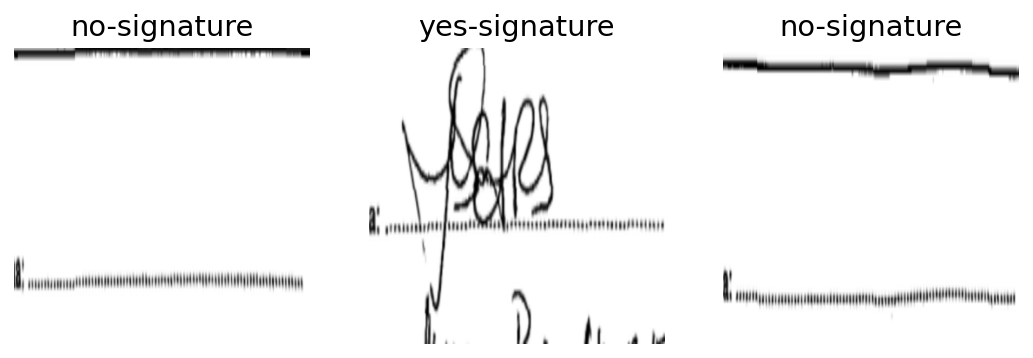

In [9]:
dls.show_batch(nrows=1, ncols=3)

In [10]:
bb

NameError: name 'bb' is not defined

In [11]:
Resize??

In [12]:
learn = cnn_learner(dls, resnet34, metrics=error_rate)
learn.freeze()

In [13]:
lr_min,lr_steep = learn.lr_find()

RuntimeError: [enforce fail at CPUAllocator.cpp:65] . DefaultCPUAllocator: can't allocate memory: you tried to allocate 216678400 bytes. Error code 12 (Cannot allocate memory)

In [ ]:
learn.fit_one_cycle(3, 3e-3)

In [ ]:
learn.unfreeze()
learn.fit_one_cycle(12, lr_max=slice(1e-6,1e-4))

In [27]:
learn_inf.get_preds(dl=dls.train)

IndexError: index 1486 is out of bounds for dimension 0 with size 1472

In [23]:
interp = ClassificationInterpretation.from_learner(dls.train, )

/home/marian/anaconda3/envs/ml/lib/python3.8/site-packages/fastprogress/fastprogress.py:74: UserWarning: Your generator is empty.
  warn("Your generator is empty.")


TypeError: __init__() missing 1 required positional argument: 'losses'

In [11]:
cnt=Counter(cls)
cnt

Counter({'yes-signature': 1731, 'linea': 32, 'no-signature': 604})

In [ ]:
min_cls = cnt[min(cnt,key=cnt.get)]

In [ ]:
idx = list(range(len(fns)))
fns = L( flatten( random.sample([fns[i] for i in idx if cls[i]==c], k = min_cls) for c in set(cls) ) )
len(fns)

In [ ]:
train,valid = RandomSplitter(seed=42)(fns) 
train,valid = (fns[train],fns[valid])
len(train),len(valid)

In [ ]:
with open('split_ds.pkl', 'wb') as f:
    pickle.dump((train,valid),f)

In [ ]:
with open('split_ds.pkl', 'rb') as f:
    (train,valid) = pickle.load(f)

In [ ]:
valid_cls = [parent_label(fn) for fn in valid]
valid_cls

In [33]:
def naive_pred(fn):
    img = Image.open(fn)
    img = Image.fromarray(naive_preprocess_signature(np.array(img)))
    return 'yes-signature' if naive_is_signature(img) else 'no-signature'
    

preds = [ naive_pred(fn) for fn in fns ]
preds


['yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'no-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'no-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'no-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'yes-signature',
 'no-signature',
 'yes-signature',
 'yes-signature',
 'yes-signatur

In [34]:
# naive cls_test acc: 0.9591700133868809
# naive cls acc: 0.9539501478664977
# myclassifier 0.9953145917001339
acc = sum([a==b for a,b in zip(cls,preds)])/len(preds)
acc

0.9539501478664977

In [5]:
learn_inf = load_learner('last_model.pkl')


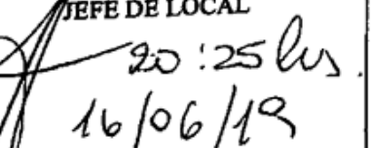

In [9]:
Image.open(fns[0])

In [10]:
cls[0]

'yes-signature'

In [12]:
learn_inf.predict(fns[0])

('yes-signature', tensor(2), tensor([1.1009e-03, 3.1721e-05, 9.9887e-01]))

In [6]:
r=list(tqdm.tqdm( (learn_inf.predict(fns[i])[0] == cls[i] for i in range(len(fns))), total=len(fns))) 

  0%|          | 0/1494 [00:00<?, ?it/s]

  0%|          | 1/1494 [00:00<06:05,  4.08it/s]

  0%|          | 2/1494 [00:00<05:43,  4.34it/s]

  0%|          | 3/1494 [00:00<05:17,  4.70it/s]

  0%|          | 4/1494 [00:00<04:44,  5.23it/s]

  0%|          | 5/1494 [00:01<05:47,  4.28it/s]

... (1,485 outputs left out)

100%|█████████▉| 1491/1494 [05:08<00:00,  4.42it/s]

100%|█████████▉| 1492/1494 [05:08<00:00,  4.09it/s]

100%|█████████▉| 1493/1494 [05:08<00:00,  4.22it/s]

100%|██████████| 1494/1494 [05:09<00:00,  4.83it/s]


In [7]:
sum(r)/len(r)

0.9953145917001339

In [10]:
lineas_idx = [i for i in range(len(fns)) if cls[i]=='linea']
lineas_idx

[1042, 1043]

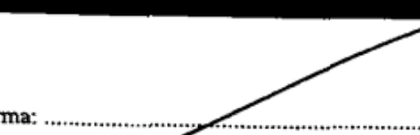

In [15]:
Image.open(fns[1043])

In [16]:
learn_inf.predict(fns[1043])

('linea', tensor(0), tensor([7.8623e-01, 7.0684e-04, 2.1306e-01]))